In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Mehtab Hassan\Desktop\Python\Mehtab python\Dataset\Trade wars 2018-2026\tariff_timeline.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 55 entries, 0 to 54
Data columns (total 16 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          55 non-null     str    
 1   imposing_country              55 non-null     str    
 2   target_country                55 non-null     str    
 3   sector                        55 non-null     str    
 4   tariff_rate_pct               55 non-null     float64
 5   prev_rate_pct                 55 non-null     float64
 6   type                          55 non-null     str    
 7   legal_basis                   42 non-null     str    
 8   estimated_trade_value_usd_bn  42 non-null     float64
 9   retaliation                   55 non-null     bool   
 10  source                        55 non-null     str    
 11  notes                         55 non-null     str    
 12  tariff_rate_delta             55 non-null     float64
 13  year              

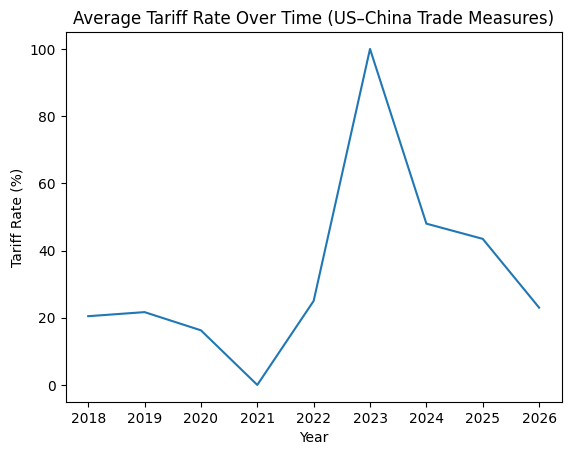

In [4]:
tariff_time = df.groupby("year")["tariff_rate_pct"].mean()

plt.figure()
plt.plot(tariff_time.index, tariff_time.values)
plt.title("Average Tariff Rate Over Time (US–China Trade Measures)")
plt.xlabel("Year")
plt.ylabel("Tariff Rate (%)")
plt.show()

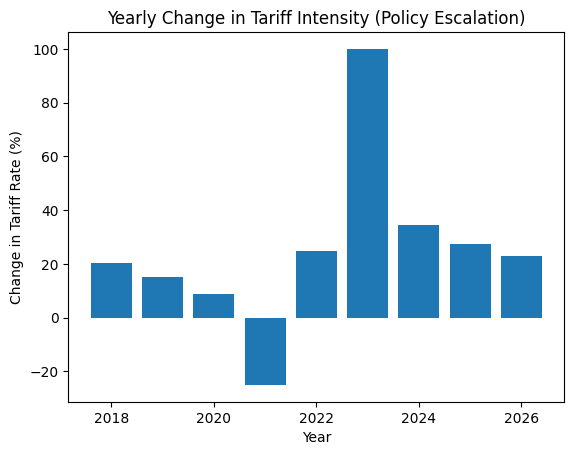

In [5]:
tariff_delta = df.groupby("year")["tariff_rate_delta"].mean()

plt.figure()
plt.bar(tariff_delta.index, tariff_delta.values)
plt.title("Yearly Change in Tariff Intensity (Policy Escalation)")
plt.xlabel("Year")
plt.ylabel("Change in Tariff Rate (%)")
plt.show()

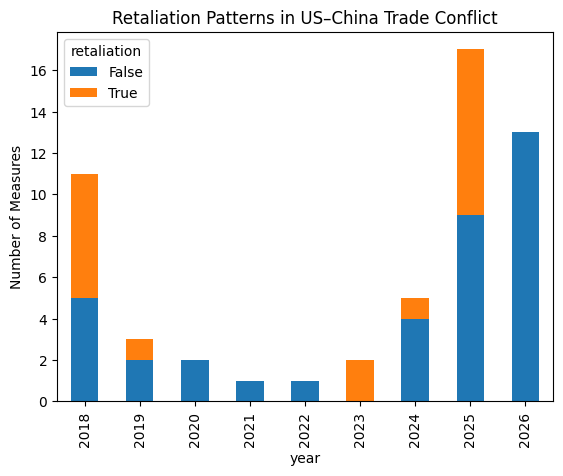

In [6]:
retaliation_counts = df.groupby(["year", "retaliation"]).size().unstack()

retaliation_counts.plot(kind="bar", stacked=True)

plt.title("Retaliation Patterns in US–China Trade Conflict")
plt.ylabel("Number of Measures")
plt.show()

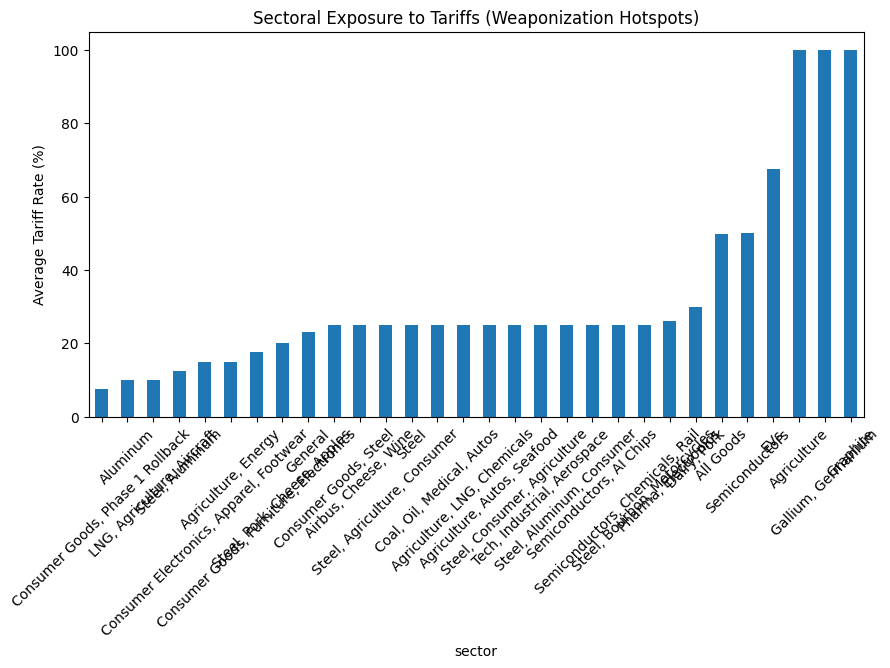

In [7]:
sector_tariff = df.groupby("sector")["tariff_rate_pct"].mean().sort_values()

plt.figure(figsize=(10,5))
sector_tariff.plot(kind="bar")
plt.title("Sectoral Exposure to Tariffs (Weaponization Hotspots)")
plt.ylabel("Average Tariff Rate (%)")
plt.xticks(rotation=45)
plt.show()

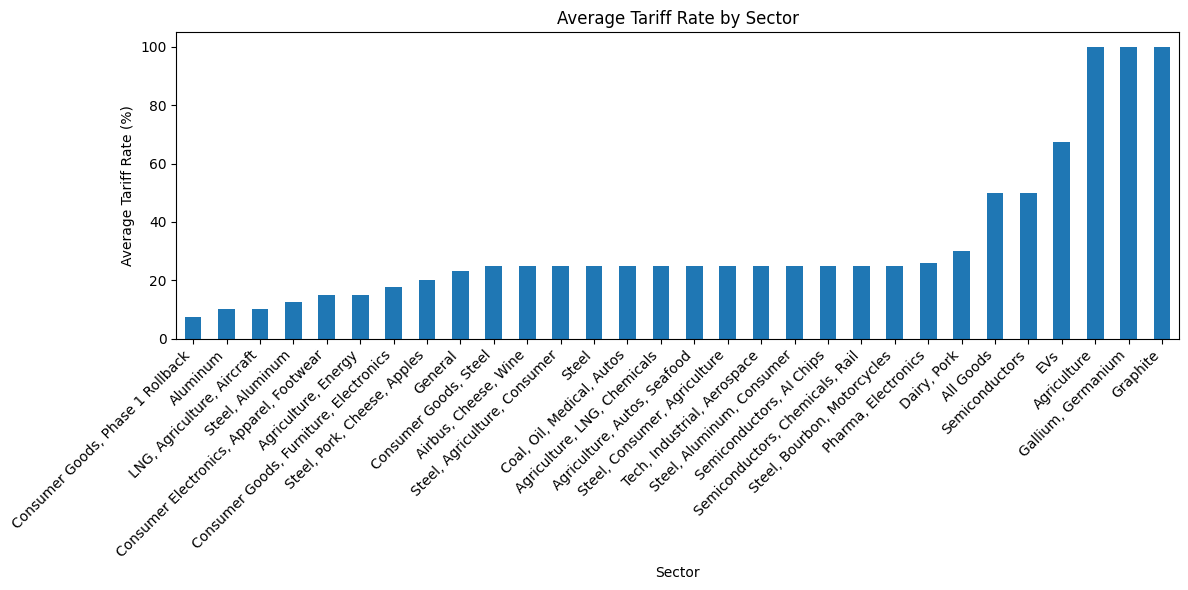

In [11]:
sector_tariff = df.groupby("sector")["tariff_rate_pct"].mean().sort_values()

plt.figure(figsize=(12,6))

sector_tariff.plot(kind="bar")

plt.title("Average Tariff Rate by Sector")
plt.xlabel("Sector")
plt.ylabel("Average Tariff Rate (%)")

plt.xticks(rotation=45, ha="right")  # fixes text overlap
plt.tight_layout()  # prevents cut-off labels

plt.show()

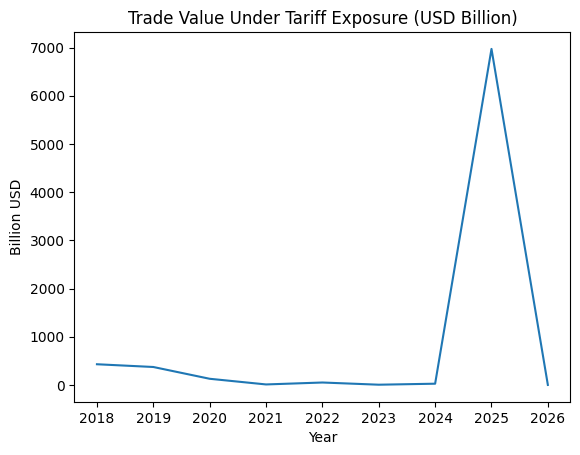

In [9]:
trade_exposure = df.groupby("year")["estimated_trade_value_usd_bn"].sum()

plt.figure()
plt.plot(trade_exposure.index, trade_exposure.values)
plt.title("Trade Value Under Tariff Exposure (USD Billion)")
plt.ylabel("Billion USD")
plt.xlabel("Year")
plt.show()

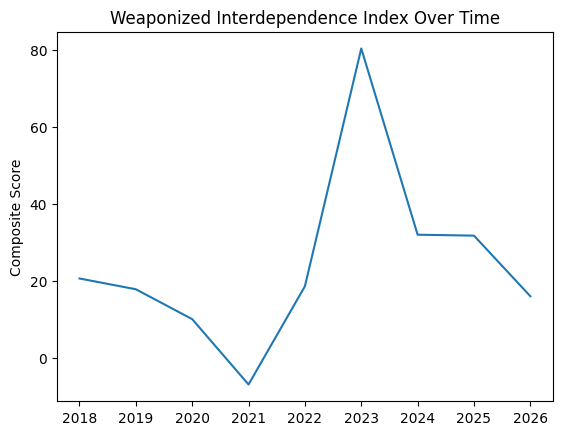

In [10]:
df["retaliation_numeric"] = df["retaliation"].astype(int)

df["weaponization_index"] = (
    df["tariff_rate_pct"] * 0.4 +
    df["tariff_rate_delta"] * 0.3 +
    df["retaliation_numeric"] * 10 +
    np.log1p(df["estimated_trade_value_usd_bn"].fillna(0)) * 0.3
)

index_by_year = df.groupby("year")["weaponization_index"].mean()

plt.figure()
plt.plot(index_by_year.index, index_by_year.values)
plt.title("Weaponized Interdependence Index Over Time")
plt.ylabel("Composite Score")
plt.show()